In [18]:
import bohnasa
import matplotlib.pyplot as plt 
import numpy as np


In [19]:
N = 500
L = 2
fock = bohnasa.fockStates_fixed_particle_number(N,L)

f = np.zeros(L)
f[0] = N


sta1 = bohnasa.single_fockstate(fock, f)
f = np.zeros(L)
f[-1] = N
sta2 = bohnasa.single_fockstate(fock, f)


sta = np.random.rand(fock.dim) #sta1 #+sta2
sta *= 1/np.linalg.norm(sta)
phi = np.full(L,1j,dtype=complex)*(-1)**np.arange(L)
#phi = np.random.rand(L)-0.5 + 1j*(np.random.rand(L)-0.5)
sta = bohnasa.coherent_state_number_projected(fock,phi)
print(sta,np.linalg.norm(sta))
hopping = bohnasa.hopping(fock)
hopping.matrix *= -1
interaction = bohnasa.interaction(fock)
interaction.matrix *= 4
test_op = hopping + interaction

def gs(X, row_vecs=True, norm = True):
    if not row_vecs:
        X = X.T
    Y = X[0:1,:].copy()
    print(X.shape)
    for i in range(1, X.shape[0]):
        proj = np.diag((X[i,:].dot(Y.T)/np.linalg.norm(Y,axis=1)**2).flat).dot(Y)
        newT = X[i,:] - proj.sum(0)
        newT *= 1/np.linalg.norm(newT)
        print("newT",newT)
        Y = np.vstack((Y, newT))
        
    if norm:
        Y = np.diag(1/np.linalg.norm(Y,axis=1)).dot(Y)
    if row_vecs:
        return Y
    else:
        return Y.T
"""
def lanzos(sta,op,krylov_dim,beta_tol=1e-8):

    v = np.zeros((krylov_dim + 1, sta.shape[0]), dtype=complex)
    T_m = np.zeros((krylov_dim+1,krylov_dim+1),dtype=complex)
    v[0] = sta/np.linalg.norm(sta)

    w_prime = op(v[0])

    alpha = np.vdot(w_prime, v[0, :])

    w = w_prime - alpha * v[0, :]

    T_m[0, 0] = alpha

    for j in range(1, krylov_dim + 1):

        beta = np.linalg.norm(w)

        if beta < beta_tol:

            # Happy breakdown
            v_happy = v[0:j, :]
            T_m_happy = T_m[0:j, 0:j]

            return v_happy, T_m_happy

        v[j, :] = w / beta
        w_prime = op(v[j, :])
        alpha = np.vdot(w_prime, v[j, :])

        w = w_prime - alpha * v[j, :] - beta * v[j - 1, :]

        T_m[j, j] = alpha
        T_m[j, j - 1] = beta
        T_m[j - 1, j] = beta

    return v, T_m

"""

[ 5.52714788e-76+4.44129333e-89j -1.23590784e-74-2.23951935e-88j
  1.95218675e-73+1.35820574e-86j -2.51521668e-72-1.84612731e-86j
  2.80364876e-71+1.64834781e-84j -2.79241164e-70+9.60805087e-85j
  2.53633383e-69+1.21775333e-82j -2.13069295e-68+3.03013885e-82j
  1.67262789e-67+6.22748445e-81j -1.23668938e-66+3.09196870e-80j
  8.66565466e-66+2.29216383e-79j -5.78366427e-65-4.50572021e-78j
  3.69204411e-64+5.78562777e-78j -2.26206519e-63-1.51838057e-76j
  1.33415282e-62+6.52390253e-77j -7.59413100e-62-4.27876407e-75j
  4.18108467e-61-2.46294496e-75j -2.23093636e-60-1.01646886e-73j
  1.15564513e-59-1.92660951e-73j -5.82064636e-59-2.02452709e-72j
  2.85449150e-58+2.46156909e-71j -1.36470796e-57-3.27546565e-71j
  6.36789864e-57+4.80485565e-70j -2.90299423e-56-3.83793679e-70j
  1.29419507e-55+8.37004232e-69j -5.64720057e-55-1.37792196e-69j
  2.41375587e-54+1.30084847e-67j -1.01134803e-53+8.43524616e-68j
  4.15673355e-53+1.79207255e-66j -1.67696573e-52+3.20656014e-66j
  6.64467913e-52+2.148351

'\ndef lanzos(sta,op,krylov_dim,beta_tol=1e-8):\n\n    v = np.zeros((krylov_dim + 1, sta.shape[0]), dtype=complex)\n    T_m = np.zeros((krylov_dim+1,krylov_dim+1),dtype=complex)\n    v[0] = sta/np.linalg.norm(sta)\n\n    w_prime = op(v[0])\n\n    alpha = np.vdot(w_prime, v[0, :])\n\n    w = w_prime - alpha * v[0, :]\n\n    T_m[0, 0] = alpha\n\n    for j in range(1, krylov_dim + 1):\n\n        beta = np.linalg.norm(w)\n\n        if beta < beta_tol:\n\n            # Happy breakdown\n            v_happy = v[0:j, :]\n            T_m_happy = T_m[0:j, 0:j]\n\n            return v_happy, T_m_happy\n\n        v[j, :] = w / beta\n        w_prime = op(v[j, :])\n        alpha = np.vdot(w_prime, v[j, :])\n\n        w = w_prime - alpha * v[j, :] - beta * v[j - 1, :]\n\n        T_m[j, j] = alpha\n        T_m[j, j - 1] = beta\n        T_m[j - 1, j] = beta\n\n    return v, T_m\n\n'

In [20]:
numbVec = fock.dim-1
v, T_m = bohnasa.lanczos(sta,test_op,numbVec,1e-5)

np.linalg.norm(v,axis=1),v.shape


np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all()


np.False_

In [21]:
print(v,v.shape)

[[ 5.52714788e-76+4.44129333e-89j -1.23590784e-74-2.23951935e-88j
   1.95218675e-73+1.35820574e-86j ...  1.95218675e-73-1.35820574e-86j
  -1.23590784e-74+2.23951935e-88j  5.52714788e-76-4.44129333e-89j]
 [ 1.95218675e-73+1.56622859e-86j -4.33030050e-72-7.89172468e-86j
   6.78501619e-71+4.71198361e-84j ...  6.78501619e-71-4.71198361e-84j
  -4.33030050e-72+7.89172468e-86j  1.95218675e-73-1.56622859e-86j]
 [ 2.80364876e-71+2.24586805e-84j -6.16884282e-70-1.13062282e-83j
   9.58750368e-69+6.64612545e-82j ...  9.58750368e-69-6.64612545e-82j
  -6.16884282e-70+1.13062282e-83j  2.80364876e-71-2.24586805e-84j]
 ...
 [-5.09283401e-18-8.35543272e-18j -1.73752816e-18-5.61032805e-18j
   4.24929368e-18+4.20922085e-18j ...  4.49898151e-18-3.99493070e-18j
  -1.45419823e-18+5.17613961e-18j -6.36571713e-18+7.93431466e-18j]
 [-2.99727336e-18-2.32466106e-18j  4.03302108e-19+1.91194262e-18j
  -3.22810486e-18+8.03220023e-18j ... -2.94919187e-18-8.41424632e-18j
  -8.14641404e-19-1.13908355e-18j -2.76925558e-

(np.False_, np.float64(9.092245022987216))

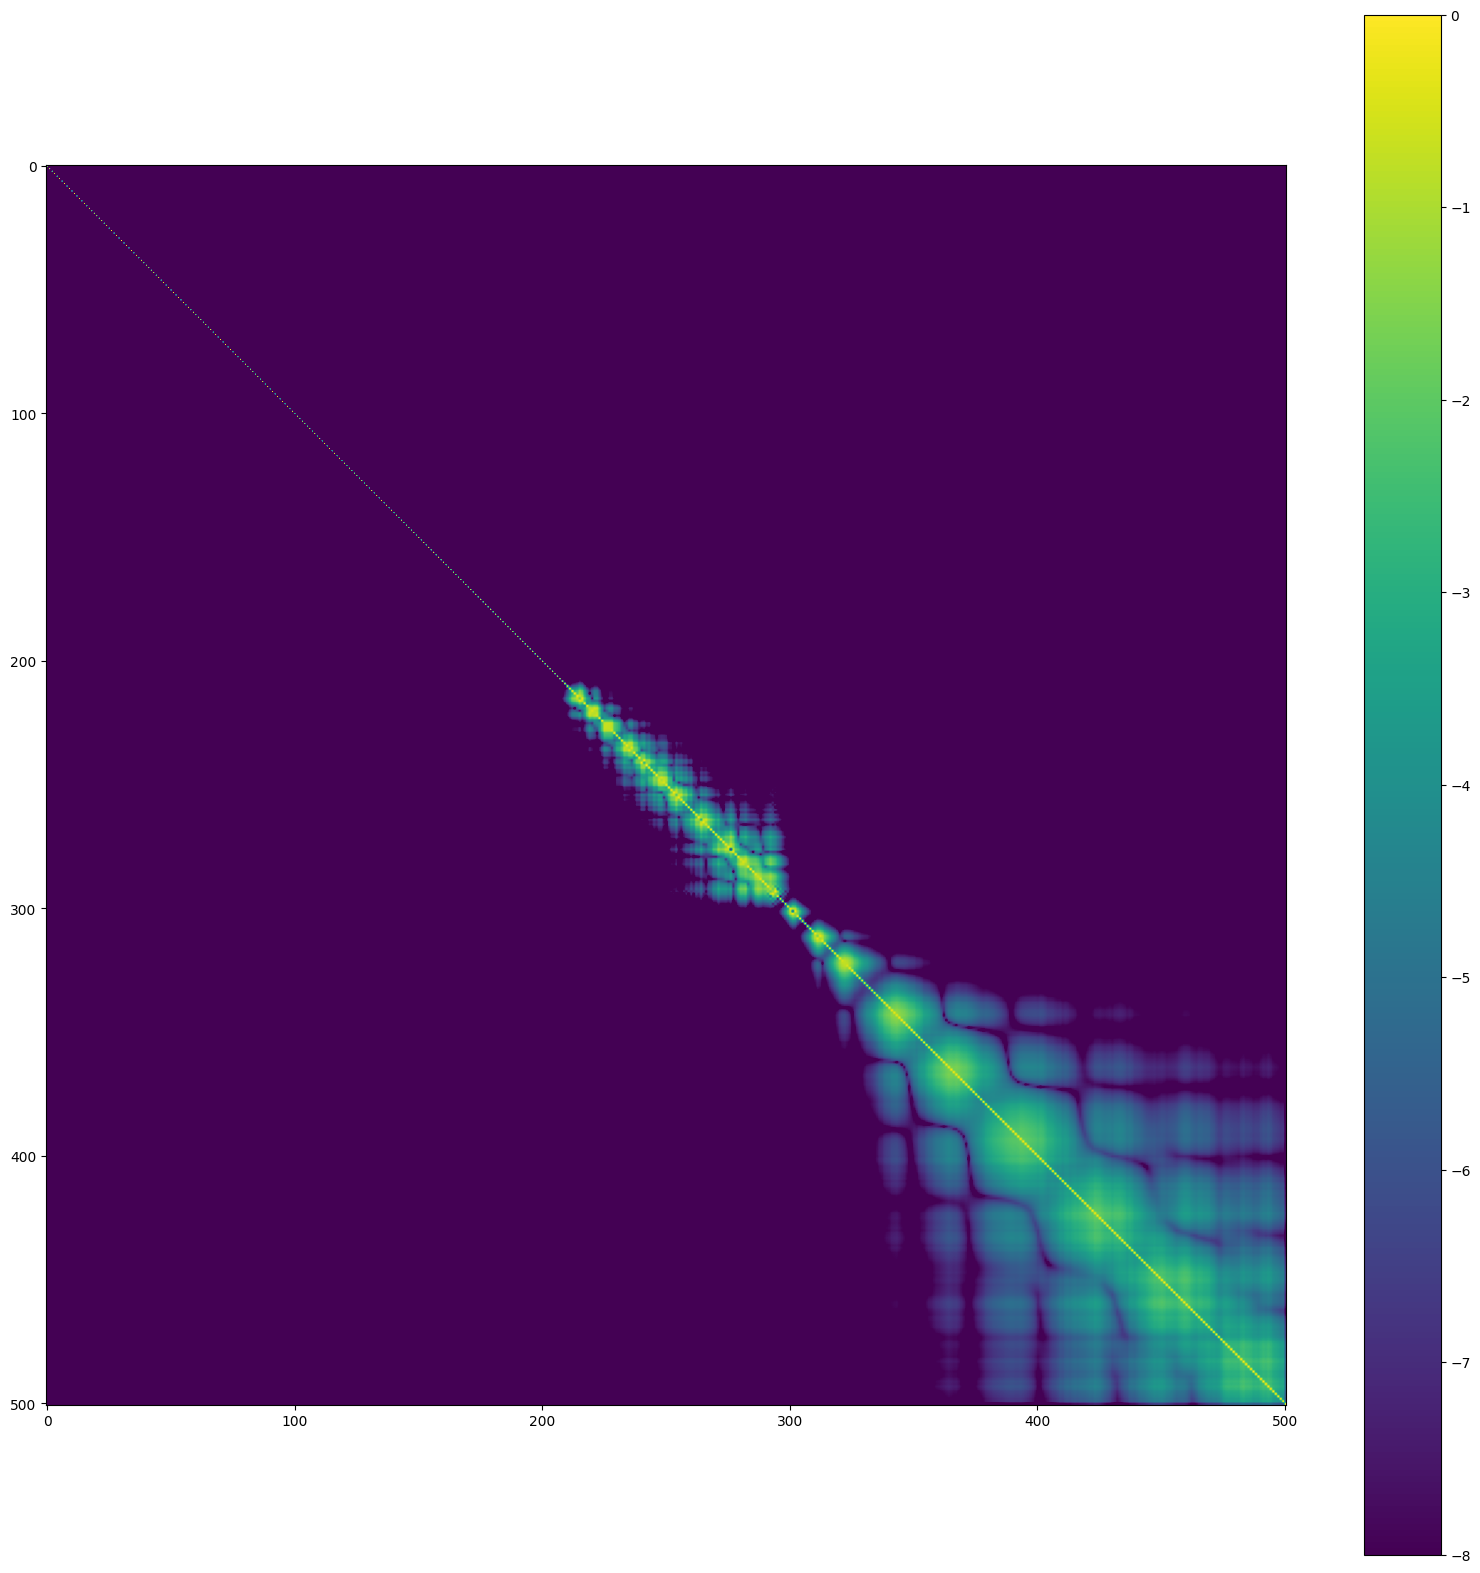

In [33]:
plt.figure(figsize=(20,20))
#plt.imshow(np.log(v@v.T).real)
plt.imshow(np.log(v@v.T +1e-13).real,vmin=-8)
##plt.imshow(T_m.real,vmin=-3)
plt.colorbar()

np.isclose(np.eye(N=v.shape[0]),(v@v.T)).all(),np.linalg.norm(np.eye(N=v.shape[0])-(v@v.T))


In [23]:
time = np.linspace(0,0.5,100)
ob = [test_op,bohnasa.number(fock,0),bohnasa.Krylov_complexity(fock,test_op,sta,numbVec)]

In [24]:

res = bohnasa.time_evolution_exact_ind(test_op,sta,time,ob)

(501,)
(501,)


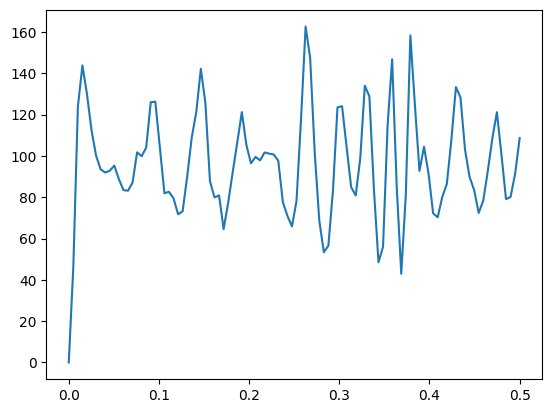

In [25]:
plt.plot(time,res[2,0])


(0.001, np.float64(1148.81268013834))

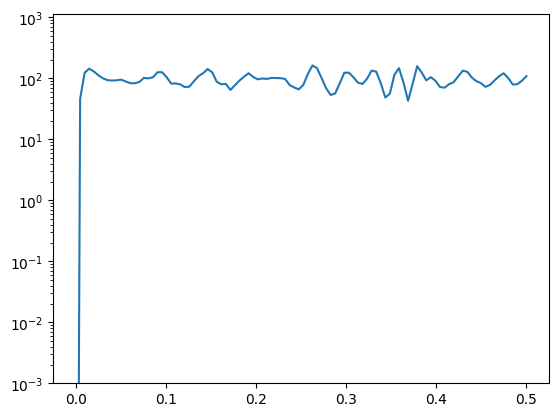

In [26]:
plt.semilogy(time,res[2,0])
plt.ylim(1e-3,None)

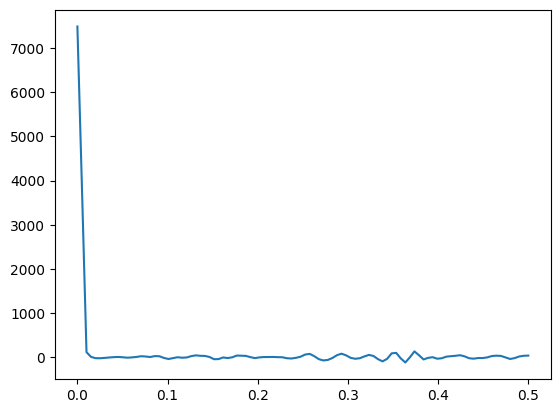

In [27]:
plt.plot(time,np.gradient(np.log(res[2,0]),time))
#plt.ylim(0,10)

In [28]:
sta

array([ 5.52714788e-76+4.44129333e-89j, -1.23590784e-74-2.23951935e-88j,
        1.95218675e-73+1.35820574e-86j, -2.51521668e-72-1.84612731e-86j,
        2.80364876e-71+1.64834781e-84j, -2.79241164e-70+9.60805087e-85j,
        2.53633383e-69+1.21775333e-82j, -2.13069295e-68+3.03013885e-82j,
        1.67262789e-67+6.22748445e-81j, -1.23668938e-66+3.09196870e-80j,
        8.66565466e-66+2.29216383e-79j, -5.78366427e-65-4.50572021e-78j,
        3.69204411e-64+5.78562777e-78j, -2.26206519e-63-1.51838057e-76j,
        1.33415282e-62+6.52390253e-77j, -7.59413100e-62-4.27876407e-75j,
        4.18108467e-61-2.46294496e-75j, -2.23093636e-60-1.01646886e-73j,
        1.15564513e-59-1.92660951e-73j, -5.82064636e-59-2.02452709e-72j,
        2.85449150e-58+2.46156909e-71j, -1.36470796e-57-3.27546565e-71j,
        6.36789864e-57+4.80485565e-70j, -2.90299423e-56-3.83793679e-70j,
        1.29419507e-55+8.37004232e-69j, -5.64720057e-55-1.37792196e-69j,
        2.41375587e-54+1.30084847e-67j, -1.01134803